# HSE RecSys Challenge 2026 — ItemKNN + EASE + SASRec

**Задача:** рекомендовать каждому пользователю 10 фильмов по истории оценок.
**Метрика соревнования:** Recall@10. **Сабмит:** CSV с колонками `user_id`, `item_id`;
во второй колонке — 10 ID через пробел.

Эта версия выполняет полный цикл: проверка данных → анализ → локальное разбиение →
популярность → ItemKNN → EASE с подбором регуляризации → SASRec → сравнение → переобучение → `submission.csv`.
Классические модели работают на CPU. SASRec использует готовую архитектуру из RePlay 0.22.0, а обучение — PyTorch. Полный запуск рассчитан на **GPU**. BERT4Rec пока не реализован. Признаки пользователей и жанров изучаем, но в эти модели не включаем.

**Перед запуском:** положите четыре исходных CSV в папку `data/` рядом с тетрадкой
или укажите `DATA_DIR` ниже. В Kaggle путь определяется автоматически при единственном наборе файлов.
Выполните **Restart Kernel and Run All**. Результаты появятся в `outputs/`.
Не требуется вручную менять состояние между ячейками.

Для преподавателя сохраняем эту тетрадку в Git вместе с инструкцией запуска и зависимостями.
Она содержит журнал гипотез, а результаты запусков дополнительно записываются в CSV.
Содержимое тетрадки не отправляется на Kaggle автоматически.

**Подтверждённые результаты Kaggle:** ItemKNN — 0,0594; EASE — **0,0860** (выше baseline_5 = 0,0821). Для SASRec результата ещё нет.

**Проверка реализации:** короткий CPU-прогон, проверка масок, checkpoint и экспорта пройдены. Полное обучение SASRec на GPU и его метрика ещё не получены. Для нового запуска сохранены чистые ячейки без результатов короткого теста.

## 1. Окружение и настройки

Нужны Python 3.11+ и пакеты ниже. Установка выполняется один раз в отдельном окружении:

```bash
python -m pip install numpy==2.3.5 pandas==2.2.3 scipy==1.17.0 matplotlib==3.10.8 threadpoolctl==3.6.0 ipykernel nbformat nbclient
```

В готовой Jupyter-среде `ipykernel`, `nbformat` и `nbclient` часто уже установлены.
Командный запуск после настройки окружения:

```bash
jupyter execute recsys_start.ipynb --timeout=1200
```

Основные вычислительные зависимости зафиксированы; фактические версии среды будут записаны в манифест.
Для SASRec нужны PyTorch 2.5–2.x и RePlay 0.22.0. На Kaggle включите **Accelerator → GPU** и **Internet → On**. Предустановленный CUDA PyTorch сохраняем; установку недостающих зависимостей выполняет раздел SASRec. После установки в уже использовавшемся окружении может потребоваться Restart Kernel and Run All.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import platform
import time
import random

import numpy as np
import pandas as pd
import scipy
from scipy import sparse, linalg
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 100)

DATA_DIR = None  # Например: Path('/kaggle/input/НАЗВАНИЕ-НАБОРА') или Path('data')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'seed': SEED,
    'k': 10,
    'validation_fraction': 0.20,
    'train_min_rating': None,
    'target_min_rating': None,
    'exclude_seen': True,
    'knn_neighbors': 100,
    'knn_shrinkage': 10.0,
    'batch_size': 256,
    'ease_regularization_grid': [100.0, 300.0, 1000.0, 3000.0, 10000.0],
    'blas_threads': 4,
    'sasrec': {
        'max_sequence_length': 100, 'window_stride': 50,
        'embedding_dim': 64, 'num_heads': 2, 'num_blocks': 2, 'dropout': 0.2,
        'batch_size': 128, 'prediction_batch_size': 256,
        'learning_rate': 0.001, 'weight_decay': 0.00001,
        'max_epochs': 50, 'patience': 8, 'gradient_clip': 1.0,
        'mixed_precision': True, 'require_cuda': True, 'num_workers': 0,
    },
}
K = CONFIG['k']
VERSIONS = {
    'python': platform.python_version(),
    **{p: metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'matplotlib', 'threadpoolctl']},
}
display(pd.Series(VERSIONS, name='version').to_frame())

# Только для проверки кода: короткое обучение на CPU, без итогового CSV.
SASREC_SMOKE_TEST = False

,version
python,3.13.15
numpy,2.1.3
pandas,2.3.3
scipy,1.16.3
matplotlib,3.10.0
threadpoolctl,3.6.0


## 2. Загрузка и проверки целостности

Читаем ID как строки: это соответствует описанию сабмита и не создаёт проблем с ведущими нулями.
У модели будет отдельное внутреннее кодирование ID.
Никакие скрытые ответы или внешние датасеты не используются.

In [2]:
FILENAMES = ['events.csv', 'user_features.csv', 'item_features.csv', 'submission_sample.csv']

def resolve_data_dir(explicit=None):
    if explicit is not None:
        candidate = Path(explicit).expanduser()
        if not all((candidate / f).is_file() for f in FILENAMES):
            raise FileNotFoundError(f'В {candidate} должны находиться все четыре CSV: {FILENAMES}')
        return candidate.resolve()
    candidates = [Path('data'), Path('.'), Path('upload'), Path('../upload')]
    if Path('/kaggle/input').exists():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('events.csv')]
    matches = sorted({p.resolve() for p in candidates if all((p / f).is_file() for f in FILENAMES)})
    if len(matches) != 1:
        raise FileNotFoundError(f'Найдено папок с данными: {len(matches)}. Укажите DATA_DIR явно: {matches}')
    return matches[0]

DATA_DIR = resolve_data_dir(DATA_DIR)
events = pd.read_csv(DATA_DIR / 'events.csv', dtype={'user_id': str, 'item_id': str})
user_features = pd.read_csv(DATA_DIR / 'user_features.csv', dtype={'user_id': str})
item_features = pd.read_csv(DATA_DIR / 'item_features.csv', dtype={'item_id': str})
sample = pd.read_csv(DATA_DIR / 'submission_sample.csv', dtype={'user_id': str, 'item_id': str})
tables = {'events': events, 'user_features': user_features, 'item_features': item_features, 'sample': sample}

assert set(events.columns) == {'user_id', 'item_id', 'rating', 'timestamp'}
assert list(sample.columns) == ['user_id', 'item_id']
assert not events.isna().any().any()
assert events['rating'].between(1, 5).all()
assert pd.api.types.is_numeric_dtype(events['timestamp'])
assert not events.duplicated(['user_id', 'item_id']).any(), 'Нужно отдельно обработать повторные оценки'
assert not events.duplicated(['user_id', 'timestamp']).any(), 'Нужна политика порядка при одинаковом timestamp'
assert user_features['user_id'].is_unique and item_features['item_id'].is_unique
assert sample['user_id'].is_unique
assert set(events['user_id']) <= set(user_features['user_id'])
assert set(events['item_id']) <= set(item_features['item_id'])
assert set(sample['user_id']) <= set(user_features['user_id'])
assert sample['item_id'].str.split().map(len).eq(K).all()
assert sample['item_id'].str.split().map(lambda xs: len(set(xs))).eq(K).all()

quality = pd.DataFrame([
    {'table': name, 'rows': len(df), 'columns': len(df.columns),
     'missing_cells': int(df.isna().sum().sum()), 'duplicate_rows': int(df.duplicated().sum())}
    for name, df in tables.items()
])
display(quality)
for name, df in tables.items():
    print(f'\n{name}: {df.dtypes.to_dict()}')
    display(df.head(3))

,table,rows,columns,missing_cells,duplicate_rows
0,events,894149,4,0,0
1,user_features,6040,3,0,0
2,item_features,3706,19,0,0
3,sample,6040,2,0,0



events: {'user_id': dtype('O'), 'item_id': dtype('O'), 'rating': dtype('int64'), 'timestamp': dtype('int64')}


,user_id,item_id,rating,timestamp
0,0,1505,4,0
1,0,3669,3,1
2,0,584,4,2



user_features: {'user_id': dtype('O'), 'gender': dtype('O'), 'age': dtype('int64')}


,user_id,gender,age
0,4855,F,1
1,4065,M,56
2,3331,M,25



item_features: {'item_id': dtype('O'), 'genre_0': dtype('int64'), 'genre_1': dtype('int64'), 'genre_2': dtype('int64'), 'genre_3': dtype('int64'), 'genre_4': dtype('int64'), 'genre_5': dtype('int64'), 'genre_6': dtype('int64'), 'genre_7': dtype('int64'), 'genre_8': dtype('int64'), 'genre_9': dtype('int64'), 'genre_10': dtype('int64'), 'genre_11': dtype('int64'), 'genre_12': dtype('int64'), 'genre_13': dtype('int64'), 'genre_14': dtype('int64'), 'genre_15': dtype('int64'), 'genre_16': dtype('int64'), 'genre_17': dtype('int64')}


,item_id,genre_0,genre_1,genre_2,genre_3,genre_4,genre_5,genre_6,genre_7,genre_8,genre_9,genre_10,genre_11,genre_12,genre_13,genre_14,genre_15,genre_16,genre_17
0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0
1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0



sample: {'user_id': dtype('O'), 'item_id': dtype('O')}


,user_id,item_id
0,0,0 1 2 3 4 5 6 7 8 9
1,1,0 1 2 3 4 5 6 7 8 9
2,2,0 1 2 3 4 5 6 7 8 9


In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

DATA_HASHES = {name: file_sha256(DATA_DIR / name) for name in FILENAMES}
user_counts = events.groupby('user_id').size()
item_counts = events.groupby('item_id').size()
cold_catalog_items = sorted(set(item_features['item_id']) - set(events['item_id']))
summary = pd.Series({
    'events': len(events),
    'users_in_events': events['user_id'].nunique(),
    'items_in_events': events['item_id'].nunique(),
    'catalog_items': len(item_features),
    'catalog_items_without_events': len(cold_catalog_items),
    'submission_users': len(sample),
    'submission_users_without_events': len(set(sample['user_id']) - set(events['user_id'])),
    'interaction_density': len(events) / (len(user_features) * len(item_features)),
})
display(summary.to_frame('value'))
display(user_counts.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).to_frame('events_per_user'))
print('Фильмы без истории:', cold_catalog_items)

,value
events,894149.000000
users_in_events,6040.000000
items_in_events,3690.000000
catalog_items,3706.000000
catalog_items_without_events,16.000000
submission_users,6040.000000
submission_users_without_events,0.000000
interaction_density,0.039945


,events_per_user
count,6040.000000
mean,148.037914
std,173.461681
min,14.000000
10%,24.000000
50%,84.500000
90%,357.000000
99%,818.610000
max,2056.000000


Фильмы без истории: ['1244', '1522', '1566', '1620', '1874', '192', '2166', '2736', '3226', '327', '3419', '3491', '404', '586', '608', '775']


## 3. Первичный анализ

Проверяем длины историй и перекос популярности. `age` трактуем как категорию,
пока не получим словарь кодирования возрастных групп. `genre_0`…`genre_17` —
жанровые индикаторы без расшифровки названий; не приписываем им названия самостоятельно.

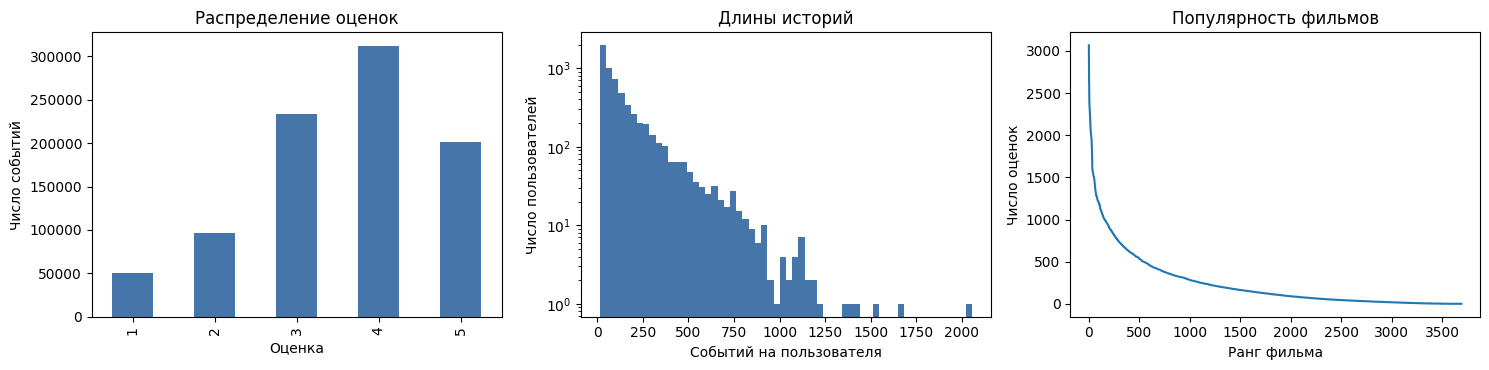

gender,F,M
age,,
1,78,144
18,298,805
25,558,1538
35,338,855
45,189,361
50,146,350
56,102,278


,genre_0,genre_1,genre_2,genre_3,genre_4,genre_5,genre_6,genre_7,genre_8,genre_9,genre_10,genre_11,genre_12,genre_13,genre_14,genre_15,genre_16,genre_17
films_with_genre,495,281,105,250,1163,201,110,1493,68,44,339,113,104,459,274,485,141,67


,value
min_timestamp,0.0
max_timestamp,2312.0
users_starting_at_zero,5471.0
median_step_inside_user,1.0


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
events['rating'].value_counts().sort_index().plot.bar(ax=axes[0], color='#4676a9')
axes[0].set(title='Распределение оценок', xlabel='Оценка', ylabel='Число событий')
axes[1].hist(user_counts, bins=60, color='#4676a9')
axes[1].set(title='Длины историй', xlabel='Событий на пользователя', ylabel='Число пользователей', yscale='log')
axes[2].plot(np.arange(1, len(item_counts) + 1), np.sort(item_counts.to_numpy())[::-1])
axes[2].set(title='Популярность фильмов', xlabel='Ранг фильма', ylabel='Число оценок')
plt.tight_layout()
plt.show()

display(pd.crosstab(user_features['age'], user_features['gender']))
genre_cols = [c for c in item_features.columns if c.startswith('genre_')]
assert item_features[genre_cols].isin([0, 1]).all().all()
display(item_features[genre_cols].sum().rename('films_with_genre').to_frame().T)

ordered_events = events.sort_values(['user_id', 'timestamp'], kind='stable')
time_summary = pd.Series({
    'min_timestamp': events['timestamp'].min(),
    'max_timestamp': events['timestamp'].max(),
    'users_starting_at_zero': int(events.groupby('user_id')['timestamp'].min().eq(0).sum()),
    'median_step_inside_user': ordered_events.groupby('user_id')['timestamp'].diff().median(),
})
display(time_summary.to_frame('value'))

### Наблюдения по предоставленной версии файлов

- 894 149 оценок; 6 040 пользователей; 3 690 фильмов с событиями и 3 706 в каталоге.
- Нет пропусков в исходных таблицах и повторных пар пользователь–фильм.
- У каждого пользователя минимум 14 событий, медиана — 84,5.
- 16 фильмов не имеют событий: коллаборативные модели не смогут выучить для них предпочтения.
- У 5 471 пользователя история начинается с `timestamp=0`, типичный шаг равен 1.
  Поле **похоже на позицию события**, но это гипотеза. Не преобразуем его в Unix-время
  и не сравниваем абсолютные значения между пользователями.

Признаки пола, возрастной группы и жанров доступны для следующих гипотез.
Пока проверяем, сколько качества даёт одна история взаимодействий.

## 4. Локальная валидация и явные допущения

У каждого пользователя скрываем последние 20% событий (округление вверх), остальные оставляем для обучения.
Сначала делим **все оценки**, затем при необходимости применяем порог rating:
так низкие оценки не исчезают из истории уже просмотренных фильмов.

Это прокси для прогноза продолжения истории, а не подтверждённая копия теста Kaggle.
В доступном описании не раскрыты алгоритм скрытия теста, порог релевантности и правила повторных рекомендаций.

Настройки первой версии:

- `target_min_rating=None`: все отложенные взаимодействия считаем целевыми;
- `train_min_rating=None`: обучение по бинарному факту взаимодействия, независимо от оценки;
- `exclude_seen=True`: не рекомендуем уже встречавшиеся в известной истории фильмы.

Это экспериментальные допущения. Изменения порогов и фильтрации — отдельные гипотезы;
значения Recall при разных наборах целевых событий напрямую не сопоставляем.
При ненулевом пороге в метрике учитываем только пользователей с непустым target и выводим их число.

Валидация использует **весь каталог**, без случайной выборки негативов.
Статистики популярности и ItemKNN обучаются только на train.

In [5]:
def split_user_tail(frame, fraction):
    assert 0 < fraction < 1
    ordered = frame.sort_values(['user_id', 'timestamp'], kind='stable').copy()
    size = ordered.groupby('user_id')['item_id'].transform('size')
    if (size < 2).any():
        raise ValueError('Для этого разбиения нужно хотя бы два события на пользователя')
    tail_size = np.ceil(size * fraction).astype(int).clip(lower=1)
    tail_size = np.minimum(tail_size, size - 1)
    position = ordered.groupby('user_id').cumcount()
    is_validation = position >= (size - tail_size)
    return ordered.loc[~is_validation].copy(), ordered.loc[is_validation].copy()

def relevant(frame, min_rating):
    return frame.copy() if min_rating is None else frame.loc[frame['rating'] >= min_rating].copy()

train_raw, valid_raw = split_user_tail(events, CONFIG['validation_fraction'])
train = relevant(train_raw, CONFIG['train_min_rating'])
valid = relevant(valid_raw, CONFIG['target_min_rating'])
targets = valid.groupby('user_id')['item_id'].agg(set).to_dict()
assert targets, 'Нет целевых взаимодействий'
assert set(train_raw.index).isdisjoint(valid_raw.index)
assert len(train_raw) + len(valid_raw) == len(events)
assert (train_raw.groupby('user_id')['timestamp'].max() < valid_raw.groupby('user_id')['timestamp'].min()).all()
assert len(train_raw.merge(valid_raw, on=['user_id', 'item_id'])) == 0
display(pd.DataFrame({
    'part': ['train_raw', 'train_after_rating_filter', 'valid_raw', 'valid_targets'],
    'events': [len(train_raw), len(train), len(valid_raw), len(valid)],
    'users': [x['user_id'].nunique() for x in [train_raw, train, valid_raw, valid]],
    'items': [x['item_id'].nunique() for x in [train_raw, train, valid_raw, valid]],
}))
print('Целевых фильмов без событий в train:', len(set(valid['item_id']) - set(train['item_id'])))

,part,events,users,items
0,train_raw,712916,6040,3652
1,train_after_rating_filter,712916,6040,3652
2,valid_raw,181233,6040,3512
3,valid_targets,181233,6040,3512


Целевых фильмов без событий в train: 38


## 5. Recall@10

Для пользователя считаем $|Top10(u)\cap Target(u)| / |Target(u)|$,
затем берём среднее по пользователям с непустым target.
Если в target 5 фильмов, а мы угадали 2, recall равен 0,4.
Порядок внутри десятки не меняет Recall@10; дубликаты не увеличивают число попаданий.

In [6]:
def recall_at_k(recommendations, ground_truth, k=10):
    rows = []
    for user_id, true_items in ground_truth.items():
        if not true_items:
            continue
        predicted = recommendations.get(user_id, [])[:k]
        if len(predicted) != len(set(predicted)):
            raise ValueError(f'Повторные рекомендации для {user_id}')
        hits = len(set(predicted) & set(true_items))
        rows.append((user_id, hits, len(true_items), hits / len(true_items)))
    per_user = pd.DataFrame(rows, columns=['user_id', 'hits', 'target_count', 'recall'])
    if per_user.empty:
        raise ValueError('Нет пользователей с непустым target')
    return float(per_user['recall'].mean()), per_user

# Проверяем формулу на примере, где ответ известен вручную.
example_score, _ = recall_at_k({'u': ['a', 'x']}, {'u': {'a', 'b', 'c', 'd', 'e'}})
assert np.isclose(example_score, 0.2)

## 6. Общие инструменты рекомендаций

Создаём разреженную матрицу пользователь–фильм. Строковые ID отображаются во внутренние индексы,
но в сабмит возвращаются исходные ID. Множество ID берём из публичных справочников;
никакие оценки из validation не попадают в обучающие матрицы.

При равных score сначала предпочитаем популярные в train фильмы, затем используем стабильный порядок ID.
Этим же механизмом заполняем рекомендации пользователям без истории.

In [7]:
user_ids = np.array(sorted(user_features['user_id'].unique()), dtype=object)
item_ids = np.array(sorted(item_features['item_id'].unique()), dtype=object)
user_to_idx = {value: index for index, value in enumerate(user_ids)}
item_to_idx = {value: index for index, value in enumerate(item_ids)}
N_USERS, N_ITEMS = len(user_ids), len(item_ids)

def interaction_matrix(frame):
    rows = frame['user_id'].map(user_to_idx)
    cols = frame['item_id'].map(item_to_idx)
    assert rows.notna().all() and cols.notna().all()
    matrix = sparse.csr_matrix(
        (np.ones(len(frame), dtype=np.float32),
         (rows.to_numpy(dtype=np.int32), cols.to_numpy(dtype=np.int32))),
        shape=(N_USERS, N_ITEMS), dtype=np.float32,
    )
    matrix.sum_duplicates()
    matrix.data[:] = 1.0
    return matrix

def popularity_scores(matrix):
    return np.asarray(matrix.sum(axis=0)).ravel().astype(np.float32)

def top_k_items(scores, popularity, seen_indices, k):
    allowed = np.ones(N_ITEMS, dtype=bool)
    if CONFIG['exclude_seen']:
        allowed[seen_indices] = False
    candidate_idx = np.flatnonzero(allowed)
    if len(candidate_idx) < k:
        raise ValueError('Недостаточно допустимых фильмов для top-k')
    order = np.lexsort((candidate_idx, -popularity[candidate_idx], -scores[candidate_idx]))
    return item_ids[candidate_idx[order[:k]]].tolist()

def recommend(model_name, matrix, seen, popularity, requested_users, similarity=None):
    result = {}
    requested_users = list(requested_users)
    for start in range(0, len(requested_users), CONFIG['batch_size']):
        batch_users = requested_users[start:start + CONFIG['batch_size']]
        batch_idx = np.array([user_to_idx[u] for u in batch_users])
        if model_name == 'itemknn' or model_name.startswith('ease_l2_'):
            if similarity is None:
                raise ValueError('Нужна обученная матрица весов')
            product = matrix[batch_idx] @ similarity
            batch_scores = product.toarray() if sparse.issparse(product) else np.asarray(product)
        elif model_name == 'popularity':
            batch_scores = np.broadcast_to(popularity, (len(batch_idx), N_ITEMS))
        else:
            raise ValueError(f'Неизвестная модель: {model_name}')
        for offset, (user_id, index) in enumerate(zip(batch_users, batch_idx)):
            seen_indices = seen.indices[seen.indptr[index]:seen.indptr[index + 1]]
            result[user_id] = top_k_items(batch_scores[offset], popularity, seen_indices, K)
    return result

def validate_recommendations(recommendations, requested_users, known_history):
    assert set(recommendations) == set(requested_users)
    catalog = set(item_ids)
    seen_by_user = known_history.groupby('user_id')['item_id'].agg(set).to_dict()
    for user_id, items in recommendations.items():
        assert len(items) == K and len(set(items)) == K
        assert set(items) <= catalog
        if CONFIG['exclude_seen']:
            assert not (set(items) & seen_by_user.get(user_id, set()))

train_matrix = interaction_matrix(train)
seen_matrix = interaction_matrix(train_raw)
popularity = popularity_scores(train_matrix)
validation_users = sorted(targets)

## 7. Гипотеза H0 — популярность

**Гипотеза:** популярные фильмы уже дают ненулевой recall.
Считаем число пользователей, оценивших каждый фильм в train, и рекомендуем самые популярные
из ещё не встречавшихся пользователю. Это технический ориентир; он не идентичен
организаторским `baseline_3/4/5`, реализации которых нам неизвестны.

In [8]:
experiment_rows = []
experiment_parameters = {}
validation_predictions = {}
per_user_metrics = {}

def register_validation(name, hypothesis, prediction, seconds, parameters=None):
    validate_recommendations(prediction, validation_users, train_raw)
    score, per_user = recall_at_k(prediction, targets, K)
    coverage = len({item for recs in prediction.values() for item in recs}) / N_ITEMS
    experiment_parameters[name] = parameters or {}
    experiment_rows.append({
        'model': name, 'hypothesis': hypothesis, 'local_recall_at_10': score,
        'parameters_json': json.dumps(experiment_parameters[name], sort_keys=True),
        'catalog_coverage_at_10': coverage, 'evaluated_users': len(per_user),
        'elapsed_seconds': round(seconds, 3),
    })
    validation_predictions[name] = prediction
    per_user_metrics[name] = per_user
    print(f'{name}: Recall@{K} = {score:.6f}; пользователей = {len(per_user)}; время = {seconds:.1f} с')

started = time.perf_counter()
pop_prediction = recommend('popularity', train_matrix, seen_matrix, popularity, validation_users)
register_validation('popularity', 'H0: глобальная популярность', pop_prediction, time.perf_counter() - started)

popularity: Recall@10 = 0.036167; пользователей = 6040; время = 1.8 с


## 8. Гипотеза H1 — ItemKNN

**Гипотеза:** персонализация по фильмам, которые часто оценивают одни и те же пользователи,
даёт recall выше глобальной популярности.

Для бинарной матрицы $X$ считаем $C=X^T X$: число общих пользователей у каждой пары фильмов.
Используем cosine similarity и понижаем надёжность пар с малым пересечением:

$$s_{ij}=\frac{C_{ij}}{\sqrt{n_i n_j}}\frac{C_{ij}}{C_{ij}+\lambda},\qquad s_{ii}=0.$$

Оставляем до 100 соседей каждого фильма. Score кандидата — сумма сходств с фильмами
из истории пользователя. При отсутствии персонального сигнала помогает популярность.
Сходства считаются блоками, чтобы не хранить полную плотную матрицу.
После ограничения соседей матрица может быть несимметричной: это ожидаемо.

In [9]:
def fit_itemknn(matrix, neighbors=100, shrinkage=10.0, batch_size=256):
    if neighbors < 1 or shrinkage < 0:
        raise ValueError('neighbors >= 1, shrinkage >= 0')
    counts = np.asarray(matrix.sum(axis=0)).ravel()
    blocks = []
    for start in range(0, N_ITEMS, batch_size):
        stop = min(start + batch_size, N_ITEMS)
        cooccurrence = (matrix[:, start:stop].T @ matrix).tocoo()
        absolute_rows = cooccurrence.row + start
        denominator = np.sqrt(counts[absolute_rows] * counts[cooccurrence.col])
        values = np.divide(cooccurrence.data, denominator,
                           out=np.zeros_like(cooccurrence.data), where=denominator > 0)
        if shrinkage:
            values *= cooccurrence.data / (cooccurrence.data + shrinkage)
        values[absolute_rows == cooccurrence.col] = 0
        similarity_block = sparse.csr_matrix(
            (values, (cooccurrence.row, cooccurrence.col)), shape=(stop - start, N_ITEMS)
        )
        similarity_block.eliminate_zeros()
        for row in range(stop - start):
            lo, hi = similarity_block.indptr[row:row + 2]
            row_values = similarity_block.data[lo:hi]
            row_indices = similarity_block.indices[lo:hi]
            if len(row_values) > neighbors:
                # Включаем все связи на границе, затем разрешаем равенства по ID.
                boundary = np.partition(row_values, -neighbors)[-neighbors]
                candidates = np.flatnonzero(row_values >= boundary)
                best = candidates[np.lexsort((row_indices[candidates], -row_values[candidates]))[:neighbors]]
                keep = np.zeros(len(row_values), dtype=bool)
                keep[best] = True
                row_values[~keep] = 0
        similarity_block.eliminate_zeros()
        blocks.append(similarity_block)
    similarity = sparse.vstack(blocks, format='csr')
    assert np.all(similarity.diagonal() == 0)
    assert np.diff(similarity.indptr).max(initial=0) <= neighbors
    return similarity

started = time.perf_counter()
similarity = fit_itemknn(train_matrix, CONFIG['knn_neighbors'], CONFIG['knn_shrinkage'], CONFIG['batch_size'])
knn_prediction = recommend('itemknn', train_matrix, seen_matrix, popularity, validation_users, similarity)
register_validation('itemknn', 'H1: сходство фильмов персонализирует рекомендации',
                    knn_prediction, time.perf_counter() - started,
                    parameters={'neighbors': CONFIG['knn_neighbors'], 'shrinkage': CONFIG['knn_shrinkage']})
print('Число ненулевых сходств:', similarity.nnz)

itemknn: Recall@10 = 0.055767; пользователей = 6040; время = 4.1 с
Число ненулевых сходств: 362318


## 9. Гипотеза H2 — EASE и небольшой подбор регуляризации

**Гипотеза:** обученные совместно веса связей между фильмами улучшают Recall@10
по сравнению с ограниченным набором ближайших соседей ItemKNN.
Используем ту же бинарную матрицу, train/validation, полный каталог и фильтрацию просмотренного.
Порог rating и локальное разбиение не меняем.

EASE решает задачу линейного восстановления истории:

$$\min_B \|X-XB\|_F^2 + \lambda\|B\|_F^2,\qquad \mathrm{diag}(B)=0.$$

Здесь $X$ — матрица пользователь–фильм, $B$ — обучаемые веса фильм–фильм,
$\lambda$ — сила регуляризации. Нулевая диагональ запрещает фильму предсказывать самого себя.
Предсказания равны $XB$; веса могут быть отрицательными, и обнулять их нельзя.

Аналитическое решение:

$$P=(X^T X+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj}\ (i\ne j),\quad B_{jj}=0.$$

Деление идёт **по столбцам**. Источник: [Harald Steck, EASE, 2019 — раздел 3](https://arxiv.org/html/1905.03375v1#S3).
Вычисляем решение через разложение Холецкого в float64; итоговые веса храним в float32.
Матрица весов для 3 706 фильмов занимает около 55 МБ; рабочая память при обучении больше.
GPU не нужен. `threadpoolctl` ограничивает число потоков BLAS.

Проверяем **ровно пять** значений $\lambda$: 100, 300, 1 000, 3 000, 10 000.
Выбор делаем по локальному Recall@10. Не подбираем параметр по Kaggle.
Матрицу $X^T X$ переиспользуем, а веса разных кандидатов не держим в памяти одновременно.

In [10]:
def fit_ease(matrix, regularization, gram=None, blas_threads=4):
    """EASE: constrained ridge regression, column-normalized inverse Gram matrix."""
    if not np.isfinite(regularization) or regularization <= 0:
        raise ValueError('regularization должна быть конечной и > 0')
    n_items = matrix.shape[1]
    if gram is None:
        x64 = matrix.astype(np.float64)
        gram = (x64.T @ x64).toarray()
    if gram.shape != (n_items, n_items) or not np.isfinite(gram).all():
        raise ValueError('Некорректная матрица X.T @ X')
    system = np.array(gram, dtype=np.float64, order='F', copy=True)
    diagonal_idx = np.diag_indices(n_items)
    system[diagonal_idx] += regularization
    with threadpool_limits(limits=blas_threads, user_api='blas'):
        factor = linalg.cho_factor(system, lower=True, overwrite_a=True, check_finite=False)
        precision = linalg.cho_solve(factor, np.eye(n_items), check_finite=False)
    precision_diagonal = precision.diagonal().copy()
    if not np.all(precision_diagonal > 0):
        raise ArithmeticError('Диагональ обратной матрицы должна быть положительной')
    precision /= -precision_diagonal[None, :]
    precision[diagonal_idx] = 0.0
    weights = precision.astype(np.float32)
    assert np.isfinite(weights).all() and np.all(weights.diagonal() == 0)
    return weights

# Независимая проверка на маленьком примере:
# каждый столбец должен совпадать с ridge-регрессией без признака самого фильма.
toy_x = sparse.csr_matrix(np.array([
    [1, 1, 0], [1, 0, 0], [1, 0, 1], [0, 1, 1], [0, 0, 1],
], dtype=np.float64))
toy_lambda = 2.0
toy_b = fit_ease(toy_x, toy_lambda, blas_threads=CONFIG['blas_threads'])
toy_g = (toy_x.T @ toy_x).toarray()
for j in range(toy_x.shape[1]):
    others = np.arange(toy_x.shape[1]) != j
    independent_solution = linalg.solve(
        toy_g[np.ix_(others, others)] + toy_lambda * np.eye(others.sum()), toy_g[others, j]
    )
    np.testing.assert_allclose(toy_b[others, j], independent_solution, rtol=1e-6, atol=1e-7)
print('EASE: проверка решения и направления нормировки пройдена')

EASE: проверка решения и направления нормировки пройдена


In [11]:
grid = CONFIG['ease_regularization_grid']
assert len(grid) > 0 and len(set(grid)) == len(grid)
assert all(np.isfinite(value) and value > 0 for value in grid)

started = time.perf_counter()
train_x64 = train_matrix.astype(np.float64)
ease_gram = (train_x64.T @ train_x64).toarray()
EASE_GRAM_SECONDS = time.perf_counter() - started
del train_x64
print(f'Общая подготовка X.T @ X: {EASE_GRAM_SECONDS:.2f} с')

ease_search_rows = []
for regularization in grid:
    started = time.perf_counter()
    model_name = f'ease_l2_{regularization:g}'
    weights = fit_ease(train_matrix, regularization, gram=ease_gram,
                       blas_threads=CONFIG['blas_threads'])
    prediction = recommend(model_name, train_matrix, seen_matrix, popularity, validation_users, weights)
    register_validation(
        model_name, 'H2: EASE улучшает Recall@10; подбор регуляризации',
        prediction, time.perf_counter() - started,
        parameters={'regularization': float(regularization)},
    )
    ease_search_rows.append({
        'regularization': float(regularization),
        'local_recall_at_10': experiment_rows[-1]['local_recall_at_10'],
        'elapsed_seconds': experiment_rows[-1]['elapsed_seconds'],
    })
    del weights
del ease_gram

ease_search_results = pd.DataFrame(ease_search_rows).sort_values(
    ['local_recall_at_10', 'regularization'], ascending=[False, True], kind='stable'
).reset_index(drop=True)
display(ease_search_results)
best_ease_lambda = float(ease_search_results.iloc[0]['regularization'])
print(f'Лучший EASE: lambda={best_ease_lambda:g}; '
      f'Recall@10={ease_search_results.iloc[0]["local_recall_at_10"]:.6f}')
print('Время кандидатов выше не включает общую однократную подготовку X.T @ X')

Общая подготовка X.T @ X: 0.92 с
ease_l2_100: Recall@10 = 0.061258; пользователей = 6040; время = 6.9 с
ease_l2_300: Recall@10 = 0.063336; пользователей = 6040; время = 6.9 с
ease_l2_1000: Recall@10 = 0.065038; пользователей = 6040; время = 6.9 с
ease_l2_3000: Recall@10 = 0.064884; пользователей = 6040; время = 6.8 с
ease_l2_10000: Recall@10 = 0.062299; пользователей = 6040; время = 6.9 с


,regularization,local_recall_at_10,elapsed_seconds
0,1000.0,0.065038,6.871
1,3000.0,0.064884,6.839
2,300.0,0.063336,6.936
3,10000.0,0.062299,6.884
4,100.0,0.061258,6.898


Лучший EASE: lambda=1000; Recall@10=0.065038
Время кандидатов выше не включает общую однократную подготовку X.T @ X


## 10. Гипотеза H3 — SASRec из RePlay

**Гипотеза:** порядок фильмов и последние события истории улучшают рекомендации.
Используем тот же train/validation, Recall@10 по всем отложенным целевым фильмам
и тот же фильтр уже встречавшихся фильмов. В качестве модели —
`replay.nn.sequential.SasRec` из **RePlay 0.22.0** (актуальный модуль вместо legacy-класса).

Обучение: `[A, B, C] → [B, C, D]`. Causal attention запрещает смотреть вперёд.
Loss — полная cross-entropy по каталогу, без sampled negatives. Значения рейтинга
по умолчанию не используются: единица означает факт взаимодействия.

Готовую архитектуру и loss берём из RePlay. Собственный цикл PyTorch нужен для
валидации с нашим Recall@10, ранней остановки и сохранения лучшей эпохи.
**Lightning используется как зависимость RePlay; Lightning Trainer здесь не нужен.**

Источники: [SASRec paper](https://arxiv.org/abs/1808.09781),
[RePlay — интерфейс SasRec](https://sb-ai-lab.github.io/RePlay/pages/modules/models.html),
[пример преподавателя](https://github.com/sb-ai-lab/RePlay/blob/main/examples/09_sasrec_example.ipynb).

### Запуск

- На Kaggle включите GPU и Internet. Подойдёт одна доступная NVIDIA GPU; `DataParallel` не используем.
- Начальная конфигурация: 100 последних событий, 64 признака, 2 блока, 2 attention-heads.
- Максимум 50 эпох, остановка после 8 эпох без улучшения Recall@10.
- Лучшая эпоха выбирается на прежнем validation. Затем модель **заново** обучается на всей истории
  ровно это число эпох; validation не участвует в обучении при выборе эпохи.
- Каждая эпоха печатает loss, recall и время. Продолжительность зависит от выбранной GPU.
  При нехватке GPU-памяти уменьшите `batch_size` до 64 или 32.

Короткая проверка кода: `SASREC_SMOKE_TEST=True`. Она использует маленькую модель,
32 истории и два обучающих батча; **это не эксперимент качества и сабмит не создаётся**.
Для полноценного CPU-обучения можно явно установить `CONFIG['sasrec']['require_cuda']=False`,
но оно может быть существенно медленнее GPU.

In [12]:
import os
import sys
import subprocess

# Устанавливаем только отсутствующие / несовпадающие зависимости SASRec.
# Версию CUDA PyTorch из Kaggle не заменяем: она должна быть совместима с GPU среды.
NN_PINNED = {'replay-rec': '0.22.0', 'lightning': '2.5.6', 'torchmetrics': '1.8.2'}
nn_install = []
for package, wanted in NN_PINNED.items():
    try:
        present = metadata.version(package)
    except metadata.PackageNotFoundError:
        present = None
    if present != wanted:
        name = 'replay-rec[torch]' if package == 'replay-rec' else package
        nn_install.append(f'{name}=={wanted}')
try:
    metadata.version('torch')
except metadata.PackageNotFoundError:
    if 'replay-rec[torch]==0.22.0' not in nn_install:
        nn_install.append('replay-rec[torch]==0.22.0')
if nn_install:
    print('Установка зависимостей SASRec:', nn_install)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *nn_install])

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import torch
from torch.utils.data import Dataset as TorchDataset, DataLoader
from replay.data import FeatureHint, FeatureSource, FeatureType
from replay.data.nn import TensorFeatureInfo, TensorFeatureSource, TensorSchema
from replay.nn.sequential import SasRec

if tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2]) < (2, 5):
    raise RuntimeError('Нужен PyTorch >= 2.5. Используйте актуальную Kaggle GPU-среду')
if metadata.version('replay-rec') != NN_PINNED['replay-rec']:
    raise RuntimeError('Перезапустите kernel после установки RePlay')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if CONFIG['sasrec']['require_cuda'] and DEVICE.type != 'cuda' and not SASREC_SMOKE_TEST:
    raise RuntimeError('GPU не обнаружена. Включите Kaggle Accelerator → GPU и перезапустите kernel. '
                       'Для проверки кода используйте SASREC_SMOKE_TEST=True.')
torch.set_num_threads(CONFIG['blas_threads'])

def seed_torch(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_torch(SEED)
VERSIONS.update({p: metadata.version(p) for p in [
    'torch', 'replay-rec', 'lightning', 'torchmetrics', 'pytorch-optimizer', 'polars', 'scikit-learn', 'pyarrow'
]})
VERSIONS['cuda_runtime'] = str(torch.version.cuda)
VERSIONS['gpu_name'] = torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'
print('Устройство:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '')
display(pd.Series({p: VERSIONS[p] for p in ['torch', 'replay-rec', 'lightning']}).to_frame('version'))

Установка зависимостей SASRec: ['replay-rec[torch]==0.22.0', 'lightning==2.5.6', 'torchmetrics==1.8.2']
Устройство: cuda Tesla T4


,version
torch,2.11.0+cu128
replay-rec,0.22.0
lightning,2.5.6


### 10.1. Последовательности и обучающие окна

Сортируем только внутри пользователя по `timestamp`. Все ID остаются в том же порядке,
что и в EASE; отдельный padding-token имеет индекс `N_ITEMS` и не является фильмом.

Для длинных историй создаём перекрывающиеся окна с шагом 50, чтобы модель обучалась
по всей доступной train-истории. Каждое окно даёт до 100 предсказаний следующего фильма.
Последнее окно всегда заканчивается последним известным событием пользователя.
При инференсе используем последние 100 известных событий, без событий validation.

Слева добавляем padding. Из loss исключаем и padding-label, и переход «padding → первый фильм».
Фильтрация просмотренного использует **всю** известную историю, включая оценки ниже train-порога,
а не только последние 100 событий. Фильмы без событий в train получают минимальный score:
их случайно инициализированные embeddings не должны создавать рекомендации.

In [13]:
PAD_ID = N_ITEMS

def histories_from_events(frame):
    ordered = frame.sort_values(['user_id', 'timestamp'], kind='stable')
    return {
        uid: np.array([item_to_idx[item] for item in group['item_id']], dtype=np.int64)
        for uid, group in ordered.groupby('user_id', sort=False)
    }

class SasRecWindows(TorchDataset):
    def __init__(self, histories, max_length, stride):
        if max_length < 1 or not 1 <= stride <= max_length:
            raise ValueError('Нужны max_length >= 1 и 1 <= stride <= max_length')
        self.histories = histories
        self.max_length = max_length
        self.windows = []
        for uid in sorted(histories):
            length = len(histories[uid])
            if length < 2:
                continue
            ends = list(range(max_length + 1, length, stride)) + [length]
            self.windows.extend((uid, end) for end in ends)
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, index):
        uid, end = self.windows[index]
        sequence = self.histories[uid][max(0, end - self.max_length - 1):end]
        tokens = np.full(self.max_length + 1, PAD_ID, dtype=np.int64)
        tokens[-len(sequence):] = sequence
        inputs, labels = tokens[:-1].copy(), tokens[1:].copy()
        target_mask = (inputs != PAD_ID) & (labels != PAD_ID)
        return {
            'tokens': torch.from_numpy(inputs),
            'labels': torch.from_numpy(labels),
            'target_mask': torch.from_numpy(target_mask),
        }

def create_sasrec(parameters):
    schema = TensorSchema([TensorFeatureInfo(
        name='item_id', feature_type=FeatureType.CATEGORICAL, is_seq=True,
        feature_hint=FeatureHint.ITEM_ID, cardinality=N_ITEMS, padding_value=PAD_ID,
        embedding_dim=parameters['embedding_dim'],
        feature_sources=[TensorFeatureSource(FeatureSource.INTERACTIONS, 'item_id')],
    )])
    return SasRec.from_params(
        schema=schema, embedding_dim=parameters['embedding_dim'], num_heads=parameters['num_heads'],
        num_blocks=parameters['num_blocks'], max_sequence_length=parameters['max_sequence_length'],
        dropout=parameters['dropout'],
    )

@torch.inference_mode()
def predict_sasrec(model, histories, requested_users, known_seen_matrix, pop_scores,
                   parameters, trained_items_mask):
    model.eval()
    predictions = {}
    known_users = [uid for uid in requested_users if len(histories.get(uid, [])) > 0]
    missing_users = [uid for uid in requested_users if len(histories.get(uid, [])) == 0]
    length = parameters['max_sequence_length']
    for start in range(0, len(known_users), parameters['prediction_batch_size']):
        batch_users = known_users[start:start + parameters['prediction_batch_size']]
        inputs = np.full((len(batch_users), length), PAD_ID, dtype=np.int64)
        for row, uid in enumerate(batch_users):
            tail = histories[uid][-length:]
            inputs[row, -len(tail):] = tail
        tokens = torch.as_tensor(inputs, device=DEVICE)
        scores = model(feature_tensors={'item_id': tokens}, padding_mask=tokens.ne(PAD_ID))['logits']
        assert scores.shape == (len(batch_users), N_ITEMS)
        scores = scores.float().cpu().numpy()
        assert np.isfinite(scores).all(), 'SASRec выдал нечисловые score'
        scores[:, ~trained_items_mask] = -np.inf
        for row, uid in enumerate(batch_users):
            index = user_to_idx[uid]
            seen = known_seen_matrix.indices[known_seen_matrix.indptr[index]:known_seen_matrix.indptr[index + 1]]
            predictions[uid] = top_k_items(scores[row], pop_scores, seen, K)
    if missing_users:
        predictions.update(recommend('popularity', None, known_seen_matrix, pop_scores, missing_users))
    return predictions

train_histories = histories_from_events(train)
SASREC_PARAMETERS = dict(CONFIG['sasrec'])
if SASREC_SMOKE_TEST:
    SASREC_PARAMETERS.update({
        'max_sequence_length': 12, 'window_stride': 6, 'embedding_dim': 16,
        'num_heads': 1, 'num_blocks': 1, 'batch_size': 16, 'prediction_batch_size': 32,
        'max_epochs': 1, 'patience': 1, 'mixed_precision': False, 'require_cuda': False,
        'max_steps_per_epoch': 2,
    })
    fit_histories = {uid: train_histories[uid] for uid in sorted(train_histories)[:32]}
else:
    fit_histories = train_histories

nn_tag_payload = {
    'parameters': SASREC_PARAMETERS, 'data_hashes': DATA_HASHES,
    'train_min_rating': CONFIG['train_min_rating'], 'validation_fraction': CONFIG['validation_fraction'],
    'target_min_rating': CONFIG['target_min_rating'], 'exclude_seen': CONFIG['exclude_seen'],
    'seed': SEED, 'torch_version': VERSIONS['torch'], 'replay_version': VERSIONS['replay-rec'],
    'smoke_test': SASREC_SMOKE_TEST,
}
NN_TAG = hashlib.sha256(json.dumps(nn_tag_payload, sort_keys=True).encode()).hexdigest()[:12]
NN_DIR = OUTPUT_DIR / 'sasrec' / NN_TAG
NN_DIR.mkdir(parents=True, exist_ok=True)
train_windows = SasRecWindows(fit_histories, SASREC_PARAMETERS['max_sequence_length'],
                              SASREC_PARAMETERS['window_stride'])
assert len(train_windows) > 0
example = train_windows[0]
assert example['target_mask'].any()
assert torch.all(example['tokens'][example['target_mask']] != PAD_ID)
assert torch.all(example['labels'][example['target_mask']] != PAD_ID)
print('Обучающих окон:', len(train_windows), '| режим:', 'SMOKE — не для сабмита' if SASREC_SMOKE_TEST else 'FULL')

Обучающих окон: 13640 | режим: FULL


### 10.2. Цикл обучения, checkpoints и проверки

После каждой эпохи считаем Recall@10 на тех же пользователях и целевых фильмах.
Сохраняем лучший checkpoint, историю loss/recall и параметры.
`best_epoch` фиксируется **до** переобучения на полной истории.

Дополнительно проверяем causal attention: замена будущих фильмов не должна менять
представления предыдущих позиций в eval-режиме. Checkpoint хранит веса, конфигурацию,
исходные ID каталога и версии. На другой GPU возможны небольшие численные отличия;
для воспроизводимости сохраняйте среду и seed.

In [14]:
def save_sasrec_checkpoint(model, parameters, epoch, path):
    payload = {
        'model_state': {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
        'parameters': parameters, 'epoch': int(epoch), 'item_ids': item_ids.tolist(),
        'versions': dict(VERSIONS), 'seed': SEED,
    }
    torch.save(payload, path)

def load_sasrec_checkpoint(path):
    payload = torch.load(path, map_location='cpu', weights_only=True)
    assert payload['item_ids'] == item_ids.tolist(), 'Изменился порядок ID каталога'
    model = create_sasrec(payload['parameters'])
    model.load_state_dict(payload['model_state'])
    return model.to(DEVICE), payload

def fit_sasrec(histories, parameters, epochs, checkpoint_path, validation_fn=None):
    seed_torch(SEED)
    model = create_sasrec(parameters).to(DEVICE)
    dataset = SasRecWindows(histories, parameters['max_sequence_length'], parameters['window_stride'])
    if len(dataset) == 0:
        raise ValueError('Нет обучающих последовательностей длиной >= 2')
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(dataset, batch_size=parameters['batch_size'], shuffle=True,
                        num_workers=parameters['num_workers'], generator=generator,
                        pin_memory=DEVICE.type == 'cuda')
    optimizer = torch.optim.AdamW(model.parameters(), lr=parameters['learning_rate'],
                                   weight_decay=parameters['weight_decay'])
    use_amp = DEVICE.type == 'cuda' and parameters['mixed_precision']
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    history, best_score, best_epoch, stale_epochs = [], -np.inf, 0, 0
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        total_loss, total_targets = 0.0, 0
        for step, batch in enumerate(loader):
            if step >= parameters.get('max_steps_per_epoch', len(loader)):
                break
            tokens = batch['tokens'].to(DEVICE, non_blocking=True)
            labels = batch['labels'].to(DEVICE, non_blocking=True)
            mask = batch['target_mask'].to(DEVICE, non_blocking=True)
            count = int(mask.sum().item())
            if not count:
                continue
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                loss = model(
                    feature_tensors={'item_id': tokens}, padding_mask=tokens.ne(PAD_ID),
                    positive_labels=labels.unsqueeze(-1), target_padding_mask=mask.unsqueeze(-1),
                )['loss']
            if not torch.isfinite(loss):
                raise FloatingPointError('Нечисловой loss: проверьте маски и learning_rate')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), parameters['gradient_clip'], error_if_nonfinite=not use_amp)
            scaler.step(optimizer)
            scaler.update()
            total_loss += float(loss.detach().item()) * count
            total_targets += count
        if not total_targets:
            raise RuntimeError('За эпоху не выполнено ни одного шага обучения')
        score = validation_fn(model) if validation_fn is not None else None
        elapsed = time.perf_counter() - started
        history.append({'epoch': epoch, 'train_loss': total_loss / total_targets,
                        'local_recall_at_10': score, 'elapsed_seconds': elapsed})
        pd.DataFrame(history).to_csv(checkpoint_path.with_suffix('.history.csv'), index=False)
        if validation_fn is None or score > best_score:
            if score is not None:
                best_score = score
            best_epoch, stale_epochs = epoch, 0
            save_sasrec_checkpoint(model, parameters, epoch, checkpoint_path)
        else:
            stale_epochs += 1
        score_text = f'{score:.6f}' if score is not None else '— (full refit)'
        print(f'Epoch {epoch:02d}/{epochs}: loss={history[-1]["train_loss"]:.4f}; '
              f'Recall@10={score_text}; {elapsed:.1f} с', flush=True)
        if validation_fn is not None and stale_epochs >= parameters['patience']:
            print(f'Early stopping: лучшая эпоха {best_epoch}, Recall@10={best_score:.6f}')
            break
    del optimizer, scaler
    model, payload = load_sasrec_checkpoint(checkpoint_path)
    return model, pd.DataFrame(history), int(payload['epoch'])

# Проверка направления attention без dropout и без padding.
seed_torch(SEED)
causal_probe = create_sasrec(SASREC_PARAMETERS).to(DEVICE).eval()
probe_len = min(6, SASREC_PARAMETERS['max_sequence_length'])
probe = torch.arange(probe_len, device=DEVICE).unsqueeze(0)
changed = probe.clone()
changed[:, -2:] = (changed[:, -2:] + 17) % N_ITEMS
with torch.inference_mode():
    prefix_a = causal_probe.body({'item_id': probe}, torch.ones_like(probe, dtype=torch.bool))
    prefix_b = causal_probe.body({'item_id': changed}, torch.ones_like(changed, dtype=torch.bool))
torch.testing.assert_close(prefix_a[:, :-2], prefix_b[:, :-2], rtol=1e-5, atol=1e-6)
del causal_probe
print('Проверка causal attention пройдена')

Проверка causal attention пройдена


In [15]:
nn_eval_users = sorted(fit_histories) if SASREC_SMOKE_TEST else validation_users
nn_eval_targets = {uid: targets[uid] for uid in nn_eval_users if uid in targets}
nn_eval_users = sorted(nn_eval_targets)
nn_trained_items = np.zeros(N_ITEMS, dtype=bool)
for sequence in fit_histories.values():
    nn_trained_items[sequence] = True

def sasrec_validation_fn(model):
    predictions = predict_sasrec(model, train_histories, nn_eval_users, seen_matrix, popularity,
                                SASREC_PARAMETERS, nn_trained_items)
    validate_recommendations(predictions, nn_eval_users, train_raw)
    return recall_at_k(predictions, nn_eval_targets, K)[0]

started = time.perf_counter()
sasrec_model, sasrec_history, sasrec_best_epoch = fit_sasrec(
    fit_histories, SASREC_PARAMETERS, SASREC_PARAMETERS['max_epochs'],
    NN_DIR / 'sasrec_validation_best.pt', validation_fn=sasrec_validation_fn,
)
SASREC_VALIDATION_SECONDS = time.perf_counter() - started
sasrec_history.to_csv(NN_DIR / 'validation_history.csv', index=False)

# Проверяем сохранение и повторное чтение checkpoint на тех же входных данных.
probe_uid = nn_eval_users[0]
probe_sequence = train_histories[probe_uid][-SASREC_PARAMETERS['max_sequence_length']:]
probe_tokens = torch.as_tensor(probe_sequence, device=DEVICE).unsqueeze(0)
with torch.inference_mode():
    sasrec_model.eval()
    logits_before = sasrec_model(feature_tensors={'item_id': probe_tokens},
                                 padding_mask=probe_tokens.ne(PAD_ID))['logits']
    restored_model, _ = load_sasrec_checkpoint(NN_DIR / 'sasrec_validation_best.pt')
    restored_model.eval()
    logits_after = restored_model(feature_tensors={'item_id': probe_tokens},
                                  padding_mask=probe_tokens.ne(PAD_ID))['logits']
torch.testing.assert_close(logits_before, logits_after, rtol=0, atol=0)
del restored_model

if not SASREC_SMOKE_TEST:
    sasrec_prediction = predict_sasrec(sasrec_model, train_histories, validation_users, seen_matrix,
                                      popularity, SASREC_PARAMETERS, nn_trained_items)
    register_validation(
        'sasrec', 'H3: causal transformer использует порядок истории', sasrec_prediction,
        SASREC_VALIDATION_SECONDS,
        parameters={**SASREC_PARAMETERS, 'best_epoch': sasrec_best_epoch, 'replay_version': '0.22.0'},
    )
else:
    print('SMOKE пройден. Короткий прогон не добавляем в сравнение качества и не экспортируем в CSV.')
display(sasrec_history)
print('Лучшая эпоха:', sasrec_best_epoch, '| checkpoint:', NN_DIR / 'sasrec_validation_best.pt')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(sasrec_history['epoch'], sasrec_history['train_loss'], marker='o', markersize=3)
axes[0].set(title='SASRec: train loss', xlabel='Эпоха', ylabel='Cross-entropy')
axes[1].plot(sasrec_history['epoch'], sasrec_history['local_recall_at_10'], marker='o', markersize=3)
axes[1].set(title='SASRec: локальный Recall@10', xlabel='Эпоха', ylabel='Recall@10')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 01/50: loss=7.5454; Recall@10=0.039563; 7.8 с
Epoch 02/50: loss=6.8425; Recall@10=0.078999; 6.8 с
Epoch 03/50: loss=6.3327; Recall@10=0.095296; 6.8 с
Epoch 04/50: loss=6.1059; Recall@10=0.106043; 6.8 с
Epoch 05/50: loss=5.9709; Recall@10=0.111400; 6.8 с
Epoch 06/50: loss=5.8846; Recall@10=0.117642; 6.8 с
Epoch 07/50: loss=5.8244; Recall@10=0.121187; 6.8 с
Epoch 08/50: loss=5.7799; Recall@10=0.121801; 6.8 с
Epoch 09/50: loss=5.7457; Recall@10=0.124340; 7.1 с
Epoch 10/50: loss=5.7177; Recall@10=0.126528; 6.9 с
Epoch 11/50: loss=5.6951; Recall@10=0.127361; 6.8 с
Epoch 12/50: loss=5.6768; Recall@10=0.128048; 6.7 с
Epoch 13/50: loss=5.6602; Recall@10=0.130173; 6.7 с
Epoch 14/50: loss=5.6458; Recall@10=0.131416; 6.8 с
Epoch 15/50: loss=5.6326; Recall@10=0.132196; 6.9 с
Epoch 16/50: loss=5.6215; Recall@10=0.132155; 6.9 с
Epoch 17/50: loss=5.6111; Recall@10=0.130650; 6.8 с
Epoch 18/50: loss=5.6025; Recall@10=0.132602; 6.8 с
Epoch 19/50: loss=5.5932; Recall@10=0.133321; 6.9 с
Epoch 20/50:

AssertionError: Tensor-likes are not equal!

Mismatched elements: 3103 / 3706 (83.7%)
Greatest absolute difference: 3.337860107421875e-06 at index (0, 365)
Greatest relative difference: 0.0033078354317694902 at index (0, 3381)

In [16]:
# Веса должны совпадать точно.
torch.testing.assert_close(
    sasrec_model.state_dict(),
    restored_model.state_dict(),
    rtol=0,
    atol=0,
)

# Для результатов вычислений допускаем небольшую погрешность.
torch.testing.assert_close(
    logits_before, logits_after,
    rtol=1e-4, atol=1e-5,
)
del restored_model

# Завершаем действия, до которых упавшая ячейка не дошла.
sasrec_prediction = predict_sasrec(
    sasrec_model, train_histories, validation_users,
    seen_matrix, popularity, SASREC_PARAMETERS, nn_trained_items,
)

# Позволяет безопасно повторно выполнить эту восстановительную ячейку.
experiment_rows[:] = [
    row for row in experiment_rows if row["model"] != "sasrec"
]

register_validation(
    "sasrec",
    "H3: causal transformer использует порядок истории",
    sasrec_prediction,
    SASREC_VALIDATION_SECONDS,
    parameters={
        **SASREC_PARAMETERS,
        "best_epoch": sasrec_best_epoch,
        "replay_version": "0.22.0",
    },
)

print("Лучшая эпоха:", sasrec_best_epoch)

sasrec: Recall@10 = 0.141546; пользователей = 6040; время = 343.3 с
Лучшая эпоха: 48


## 11. Сравнение и разбор результатов

Выбираем модель по локальному Recall@10. Покрытие каталога — диагностическая величина,
а не критерий выбора в этом соревновании. Первый сабмит ItemKNN получил **0,0594 на Kaggle** (скриншот пользователя, 29.10.2026). Сабмит EASE получил **0,0860 на Kaggle** (скриншот пользователя, 29.10.2026), выше baseline_5 = 0,0821. Результат SASRec пока неизвестен.
Смотрим, как качество зависит от длины доступной истории.

In [17]:
results = pd.DataFrame(experiment_rows).sort_values(
    ['local_recall_at_10', 'model'], ascending=[False, True], kind='stable'
).reset_index(drop=True)
display(results)
best_model = results.iloc[0]['model']
best_parameters = experiment_parameters[best_model]
print('Выбрана модель:', best_model, best_parameters)

segments = []
history_lengths = train_raw.groupby('user_id').size()
for name, metrics in per_user_metrics.items():
    part = metrics.copy()
    part['history_length'] = part['user_id'].map(history_lengths)
    part['history_group'] = pd.cut(part['history_length'], [0, 30, 100, 300, np.inf],
                                   labels=['1–30', '31–100', '101–300', '301+'])
    grouped = part.groupby('history_group', observed=True)['recall'].agg(['mean', 'count']).reset_index()
    grouped.insert(0, 'model', name)
    segments.append(grouped)
display(pd.concat(segments, ignore_index=True))

pop_score = float(results.loc[results['model'] == 'popularity', 'local_recall_at_10'].iloc[0])
knn_score = float(results.loc[results['model'] == 'itemknn', 'local_recall_at_10'].iloc[0])
best_ease_score = float(ease_search_results.iloc[0]['local_recall_at_10'])
display(Markdown(
    f'**Локальный результат:** popularity = **{pop_score:.6f}**, '
    f'ItemKNN = **{knn_score:.6f}**, лучший EASE = **{best_ease_score:.6f}** '
    f'(lambda={best_ease_lambda:g}). Разница EASE − ItemKNN = **{best_ease_score - knn_score:+.6f}**. '
    f'Для финального переобучения выбрана **{best_model}**. '
    'EASE выбран из пяти кандидатов на одном validation: оценка после подбора может быть оптимистичной. '
    'Подтверждённая метрика EASE на Kaggle — 0,0860; для SASRec она пока неизвестна.'
))

if not SASREC_SMOKE_TEST:
    nn_score = float(results.loc[results['model'] == 'sasrec', 'local_recall_at_10'].iloc[0])
    display(Markdown(f'**SASRec:** {nn_score:.6f}; лучший EASE: {best_ease_score:.6f}; '
                     f'разница: {nn_score - best_ease_score:+.6f}. '
                     'Это локальное сравнение, а не прогноз результата Kaggle.'))


,model,hypothesis,local_recall_at_10,parameters_json,catalog_coverage_at_10,evaluated_users,elapsed_seconds
0,sasrec,H3: causal transformer использует порядок истории,0.141546,"{""batch_size"": 128, ""best_epoch"": 48, ""dropout"": 0.2, ""embedding_dim"": 64, ""gradient_clip"": 1.0,...",0.606044,6040,343.293
1,ease_l2_1000,H2: EASE улучшает Recall@10; подбор регуляризации,0.065038,"{""regularization"": 1000.0}",0.252833,6040,6.871
2,ease_l2_3000,H2: EASE улучшает Recall@10; подбор регуляризации,0.064884,"{""regularization"": 3000.0}",0.204263,6040,6.839
3,ease_l2_300,H2: EASE улучшает Recall@10; подбор регуляризации,0.063336,"{""regularization"": 300.0}",0.305990,6040,6.936
4,ease_l2_10000,H2: EASE улучшает Recall@10; подбор регуляризации,0.062299,"{""regularization"": 10000.0}",0.148948,6040,6.884
5,ease_l2_100,H2: EASE улучшает Recall@10; подбор регуляризации,0.061258,"{""regularization"": 100.0}",0.344576,6040,6.898
6,itemknn,H1: сходство фильмов персонализирует рекомендации,0.055767,"{""neighbors"": 100, ""shrinkage"": 10.0}",0.104965,6040,4.146
7,popularity,H0: глобальная популярность,0.036167,{},0.021587,6040,1.849


Выбрана модель: sasrec {'max_sequence_length': 100, 'window_stride': 50, 'embedding_dim': 64, 'num_heads': 2, 'num_blocks': 2, 'dropout': 0.2, 'batch_size': 128, 'prediction_batch_size': 256, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'max_epochs': 50, 'patience': 8, 'gradient_clip': 1.0, 'mixed_precision': True, 'require_cuda': True, 'num_workers': 0, 'best_epoch': 48, 'replay_version': '0.22.0'}


,model,history_group,mean,count
0,popularity,1–30,0.046076,1516
1,popularity,31–100,0.039595,2321
2,popularity,101–300,0.028430,1657
3,popularity,301+,0.017557,546
4,itemknn,1–30,0.094555,1516
5,itemknn,31–100,0.058438,2321
6,itemknn,101–300,0.029140,1657
7,itemknn,301+,0.017530,546
8,ease_l2_100,1–30,0.137809,1516
9,ease_l2_100,31–100,0.051563,2321


**Локальный результат:** popularity = **0.036167**, ItemKNN = **0.055767**, лучший EASE = **0.065038** (lambda=1000). Разница EASE − ItemKNN = **+0.009270**. Для финального переобучения выбрана **sasrec**. EASE выбран из пяти кандидатов на одном validation: оценка после подбора может быть оптимистичной. Подтверждённая метрика EASE на Kaggle — 0,0860; для SASRec она пока неизвестна.

**SASRec:** 0.141546; лучший EASE: 0.065038; разница: +0.076509. Это локальное сравнение, а не прогноз результата Kaggle.

## 12. Переобучение на всей истории и экспорт сабмита

Фиксируем лучший подход и его параметры по validation, затем возвращаем validation в обучение. Для EASE используем выбранную lambda без повторного подбора на всей истории.
Формируем рекомендации для пользователей из sample в исходном порядке.
Низкие оценки также входят в фильтр уже встречавшихся фильмов.
Каждый пользователь получает ровно 10 различных ID из каталога.

Для SASRec всегда создаём отдельный `submission_sasrec.csv`, даже если локально победил EASE. `submission.csv` содержит рекомендации лучшей модели по validation. SASRec переобучается с нуля ровно `best_epoch` эпох, без validation и early stopping на полной истории. В smoke-режиме полный refit и экспорт отключены.

In [18]:
if SASREC_SMOKE_TEST:
    print('SMOKE: полный refit и экспорт CSV отключены')
else:
    started = time.perf_counter()
    full_train = relevant(events, CONFIG['train_min_rating'])
    full_matrix = interaction_matrix(full_train)
    full_seen = interaction_matrix(events)
    full_popularity = popularity_scores(full_matrix)
    full_similarity = None
    full_histories = histories_from_events(full_train)
    full_nn_mask = np.zeros(N_ITEMS, dtype=bool)
    for sequence in full_histories.values():
        full_nn_mask[sequence] = True
    print(f'Полное обучение SASRec: {sasrec_best_epoch} эпох')
    # Освобождаем валидационную модель перед обучением новой.
    sasrec_model.to('cpu')
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    full_sasrec_model, full_sasrec_history, _ = fit_sasrec(
        full_histories, SASREC_PARAMETERS, sasrec_best_epoch, NN_DIR / 'sasrec_full.pt', validation_fn=None
    )
    full_sasrec_predictions = predict_sasrec(
        full_sasrec_model, full_histories, sample['user_id'].tolist(), full_seen,
        full_popularity, SASREC_PARAMETERS, full_nn_mask
    )
    validate_recommendations(full_sasrec_predictions, sample['user_id'].tolist(), events)
    sasrec_submission = sample[['user_id']].copy()
    sasrec_submission['item_id'] = sasrec_submission['user_id'].map(
        lambda uid: ' '.join(full_sasrec_predictions[uid])
    )
    SASREC_SUBMISSION_PATH = OUTPUT_DIR / 'submission_sasrec.csv'
    sasrec_submission.to_csv(SASREC_SUBMISSION_PATH, index=False)
    pd.testing.assert_frame_equal(
        pd.read_csv(SASREC_SUBMISSION_PATH, dtype=str), sasrec_submission.reset_index(drop=True)
    )
    if best_model == 'itemknn':
        full_similarity = fit_itemknn(full_matrix, CONFIG['knn_neighbors'], CONFIG['knn_shrinkage'], CONFIG['batch_size'])
    elif best_model.startswith('ease_l2_'):
        full_similarity = fit_ease(full_matrix, best_parameters['regularization'],
                                   blas_threads=CONFIG['blas_threads'])

    if best_model == 'sasrec':
        final_predictions = full_sasrec_predictions
    else:
        final_predictions = recommend(best_model, full_matrix, full_seen, full_popularity,
                                      sample['user_id'].tolist(), full_similarity)
    validate_recommendations(final_predictions, sample['user_id'].tolist(), events)

    submission = sample[['user_id']].copy()
    submission['item_id'] = submission['user_id'].map(lambda uid: ' '.join(final_predictions[uid]))
    assert submission['user_id'].tolist() == sample['user_id'].tolist()
    assert list(submission.columns) == list(sample.columns)
    assert not submission.isna().any().any()
    assert submission['item_id'].str.split().map(len).eq(K).all()

    SUBMISSION_PATH = OUTPUT_DIR / 'submission.csv'
    submission.to_csv(SUBMISSION_PATH, index=False)
    MODEL_SUBMISSION_PATH = OUTPUT_DIR / f'submission_{best_model}.csv'
    submission.to_csv(MODEL_SUBMISSION_PATH, index=False)
    roundtrip = pd.read_csv(SUBMISSION_PATH, dtype=str)
    pd.testing.assert_frame_equal(roundtrip, submission.reset_index(drop=True))
    FINAL_SECONDS = time.perf_counter() - started
    display(submission.head())
    print(f'Сохранён {SUBMISSION_PATH}: {len(submission)} строк; финальное обучение и прогноз = {FINAL_SECONDS:.1f} с')

Полное обучение SASRec: 48 эпох
Epoch 01/48: loss=7.5142; Recall@10=— (full refit); 3.5 с
Epoch 02/48: loss=6.6752; Recall@10=— (full refit); 3.4 с
Epoch 03/48: loss=6.2592; Recall@10=— (full refit); 3.4 с
Epoch 04/48: loss=6.0691; Recall@10=— (full refit); 3.4 с
Epoch 05/48: loss=5.9600; Recall@10=— (full refit); 3.4 с
Epoch 06/48: loss=5.8919; Recall@10=— (full refit); 3.4 с
Epoch 07/48: loss=5.8447; Recall@10=— (full refit); 3.4 с
Epoch 08/48: loss=5.8108; Recall@10=— (full refit); 3.4 с
Epoch 09/48: loss=5.7852; Recall@10=— (full refit); 3.3 с
Epoch 10/48: loss=5.7640; Recall@10=— (full refit); 3.3 с
Epoch 11/48: loss=5.7459; Recall@10=— (full refit); 3.3 с
Epoch 12/48: loss=5.7297; Recall@10=— (full refit); 3.3 с
Epoch 13/48: loss=5.7162; Recall@10=— (full refit); 3.3 с
Epoch 14/48: loss=5.7040; Recall@10=— (full refit); 3.4 с
Epoch 15/48: loss=5.6945; Recall@10=— (full refit); 3.4 с
Epoch 16/48: loss=5.6836; Recall@10=— (full refit); 3.3 с
Epoch 17/48: loss=5.6754; Recall@10=— (f

,user_id,item_id
0,0,3002 213 1461 1527 2275 1171 1044 2454 3411 1160
1,1,1686 232 2338 2336 1868 3311 3656 1822 463 452
2,2,1687 2354 702 488 3035 570 2338 2185 1956 3539
3,3,2363 802 3013 2814 810 1223 2564 3035 1543 762
4,4,1545 802 1337 3035 1086 2814 2653 488 2185 3030


Сохранён outputs/submission.csv: 6040 строк; финальное обучение и прогноз = 166.5 с


## 13. Журнал экспериментов и воспроизводимость

Сохраняем параметры, версии и SHA-256 исходных файлов, чтобы отличать изменение модели от изменения данных.
`experiment_log.csv` хранит локальные эксперименты, `submission_log.csv` — сформированные сабмиты.
Повторный запуск с той же конфигурацией обновляет соответствующие строки, сохраняя ручные заметки
и введённый результат Kaggle. Каждой фактической отправке назначайте уникальный submission_id. При изменении конфигурации создаются новые записи.

После **каждой реальной отправки** допишите строку в `submission_log.csv`, если отправок было несколько,
и внесите score, дату и комментарий. Эта тетрадка сама ничего не отправляет.
Не подменяйте неизвестную метрику Kaggle локальной метрикой.

История эпох и checkpoints SASRec находятся в `outputs/sasrec/<run_tag>/`. Добавлена таблица подтверждённых результатов Kaggle по скриншотам пользователя. Изменение состава экспериментов создаёт новый run_id; это не означает повторную отправку прежних моделей.

In [19]:
if SASREC_SMOKE_TEST:
    print('SMOKE: журнал сабмитов и финальный манифест не изменяем')
else:
    MODEL_IMPLEMENTATION_VERSION = 'cpu_and_sasrec_v3'
    run_payload = {'config': CONFIG, 'data_hashes': DATA_HASHES,
                   'implementation': MODEL_IMPLEMENTATION_VERSION, 'versions': VERSIONS}
    RUN_ID = hashlib.sha256(json.dumps(run_payload, sort_keys=True).encode()).hexdigest()[:12]

    def upsert_log(path, new_rows, key, preserve=()):
        if path.exists():
            old = pd.read_csv(path, dtype={key: str})
            old_index = old.set_index(key)
            for column in preserve:
                if column in old_index:
                    saved = new_rows[key].map(old_index[column])
                    new_rows[column] = saved.where(saved.notna(), new_rows[column])
            old = old.loc[~old[key].isin(new_rows[key])]
            combined = pd.concat([old, new_rows], ignore_index=True)
        else:
            combined = new_rows
        combined.to_csv(path, index=False)

    local_log = results.copy()
    local_log.insert(0, 'experiment_id', [f'{RUN_ID}_{name}' for name in local_log['model']])
    local_log['run_id'] = RUN_ID
    local_log['config_json'] = json.dumps(CONFIG, ensure_ascii=False, sort_keys=True)
    local_log['notes'] = ''
    upsert_log(OUTPUT_DIR / 'experiment_log.csv', local_log, 'experiment_id', preserve=['notes'])

    immutable_submission = OUTPUT_DIR / f'submission_{RUN_ID}_{best_model}.csv'
    submission.to_csv(immutable_submission, index=False)
    submission_log = pd.DataFrame([{
        'submission_id': f'{RUN_ID}_{best_model}', 'run_id': RUN_ID, 'model': best_model,
        'filename': immutable_submission.name, 'sha256': file_sha256(immutable_submission),
        'local_recall_at_10': float(results.iloc[0]['local_recall_at_10']),
        'kaggle_score': np.nan, 'submitted_at': '', 'notes': 'Сформирован; отправка на Kaggle ещё не подтверждена',
    }])
    upsert_log(OUTPUT_DIR / 'submission_log.csv', submission_log, 'submission_id',
               preserve=['kaggle_score', 'submitted_at', 'notes'])

    manifest = {
        'run_id': RUN_ID, **run_payload, 'selected_model': best_model,
        'selected_parameters': best_parameters, 'ease_gram_seconds': EASE_GRAM_SECONDS,
        'sasrec_best_epoch': sasrec_best_epoch, 'sasrec_validation_seconds': SASREC_VALIDATION_SECONDS,
        'sasrec_checkpoint_directory': str(NN_DIR),
        'sasrec_submission_sha256': file_sha256(SASREC_SUBMISSION_PATH),
        'sasrec_epoch_history': sasrec_history.to_dict(orient='records'),
        'ease_search_results': ease_search_results.to_dict(orient='records'),
        'validation_results': results.to_dict(orient='records'),
        'final_fit_and_predict_seconds': FINAL_SECONDS,
        'submission_rows': len(submission), 'submission_sha256': file_sha256(SUBMISSION_PATH),
        'assumptions': [
            'per-user chronological last-20-percent holdout; official split unknown',
            'all held-out ratings are targets by default; official relevance threshold unknown',
            'exclude known user-item pairs by default; official repeat policy unknown',
        ],
    }
    (OUTPUT_DIR / f'run_manifest_{RUN_ID}.json').write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    core_versions = '\n'.join(f'{name}=={VERSIONS[name]}' for name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'threadpoolctl'])
    (OUTPUT_DIR / 'requirements_core.txt').write_text(core_versions + '\n', encoding='utf-8')
    display(pd.read_csv(OUTPUT_DIR / 'submission_log.csv').tail())
    print('Артефакты запуска:', sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file()))

    # Для отдельного SASRec-сабмита сохраняем самостоятельную запись, если общая лучшая модель другая.
    if best_model != 'sasrec':
        nn_submission_log = pd.DataFrame([{
            'submission_id': f'{RUN_ID}_sasrec', 'run_id': RUN_ID, 'model': 'sasrec',
            'filename': SASREC_SUBMISSION_PATH.name, 'sha256': file_sha256(SASREC_SUBMISSION_PATH),
            'local_recall_at_10': nn_score, 'kaggle_score': np.nan, 'submitted_at': '',
            'notes': 'Сформирован SASRec; отправка на Kaggle ещё не подтверждена',
        }])
        upsert_log(OUTPUT_DIR / 'submission_log.csv', nn_submission_log, 'submission_id',
                   preserve=['kaggle_score', 'submitted_at', 'notes'])

    public_results = pd.DataFrame([
        {'model': 'itemknn', 'kaggle_recall_at_10': 0.0594,
         'source': 'Скриншот пользователя, 29.10.2026'},
        {'model': 'ease_l2_1000', 'kaggle_recall_at_10': 0.0860,
         'source': 'Скриншот пользователя, 29.10.2026'},
    ])
    public_results.to_csv(OUTPUT_DIR / 'confirmed_kaggle_results.csv', index=False)
    nn_versions = {p: VERSIONS[p] for p in ['torch', 'replay-rec', 'lightning', 'torchmetrics']}
    # CUDA/CPU build tags remain in the manifest; requirements keep the base torch version.
    nn_versions['torch'] = nn_versions['torch'].split('+')[0]
    (OUTPUT_DIR / 'requirements_sasrec.txt').write_text(
        '\n'.join(f'{name}=={version}' for name, version in nn_versions.items()) + '\n', encoding='utf-8'
    )
    display(public_results)
    print('SASRec для Kaggle:', SASREC_SUBMISSION_PATH)


,submission_id,run_id,model,filename,sha256,local_recall_at_10,kaggle_score,submitted_at,notes
0,7f1dfc148dbd_sasrec,7f1dfc148dbd,sasrec,submission_7f1dfc148dbd_sasrec.csv,c6ef549014336f93ff099cd6e0fd85a806a0155fca5ec0c6a051999db1c7a443,0.141546,NaN,NaN,Сформирован; отправка на Kaggle ещё не подтверждена


Артефакты запуска: ['experiment_log.csv', 'requirements_core.txt', 'run_manifest_7f1dfc148dbd.json', 'submission.csv', 'submission_7f1dfc148dbd_sasrec.csv', 'submission_log.csv', 'submission_sasrec.csv']


,model,kaggle_recall_at_10,source
0,itemknn,0.0594,"Скриншот пользователя, 29.10.2026"
1,ease_l2_1000,0.0860,"Скриншот пользователя, 29.10.2026"


SASRec для Kaggle: outputs/submission_sasrec.csv


## 14. Следующие гипотезы и вопросы к организатору

| Статус | Гипотеза / вопрос | Как проверим |
|---|---|---|
| Выполнено | H0: глобальная популярность даёт стартовое качество | Локальный Recall@10 в таблице результатов |
| Выполнено | H1: ItemKNN улучшает персонализацию | То же разбиение и та же метрика |
| Выполнено | H2: EASE с подбором регуляризации улучшает персонализацию | Пять значений lambda, прежнее разбиение |
| Запланировано | H6: последние взаимодействия полезнее старых | Веса или ограничение длины истории |
| Реализовано, требуется полный GPU-запуск | H3: SASRec из RePlay улучшает Recall@10 | Те же train/validation, весь каталог, одинаковая фильтрация |
| Запланировано | H4: порог оценки в обучении улучшает сигнал | Меняем train_min_rating, оставляя target неизменным |
| Запланировано | H5: жанровые признаки помогают редким фильмам | Отдельная модель или смешивание score |
| Уточнить | Как сформирован скрытый тест и что считается релевантным? | Описание / ответ преподавателя |
| Уточнить | Исключать ли уже оценённые фильмы? | Описание / ответ преподавателя |
| Уточнить | Численные значения baseline_3/4/5 | Leaderboard / ответ преподавателя |

Первый сабмит ItemKNN: Kaggle Recall@10 = **0,0594**, выше baseline_4 = 0,0450, ниже baseline_5 = 0,0821 (по скриншоту пользователя).

Сабмит EASE: **0,0860**, выше baseline_5 = 0,0821. Теперь запускаем SASRec на GPU, сравниваем локальный Recall@10, отправляем `submission_sasrec.csv` и фиксируем реальный Kaggle score. Архитектура использует RePlay 0.22.0; исходный пример преподавателя:
[RePlay — SASRec notebook](https://github.com/sb-ai-lab/RePlay/blob/main/examples/09_sasrec_example.ipynb).
Версии RePlay и Lightning закреплены, версия CUDA PyTorch записывается из фактической среды. Если SASRec окажется хуже EASE, сохраняем EASE как лучшее решение; следующая гипотеза — ограниченный подбор длины истории или смешивание рекомендаций.